  REAL PHYSIOLOGICAL PARAMETERS
  V_safe (Vmax safe routes) = 0.7858 mg/(L·min)
  K_m    (Michaelis)       = 151.16 mg/L  (1000.00 mM)
  k_cyp  (CYP450)          = 0.000404 min⁻¹
  b      (NAPQI neutral.)  = 0.0100 1/(mM·min)
  kprod  (GSH synthesis)     = 0.019254 mM/min
  kdeg   (GSH degradation)       = 0.00385 min⁻¹  (t½=180.0 min)
  d      (GSH consumption)     = 0.0050 1/(mM·min)

  G* = kprod/kdeg          = 5.00 mM  (expected: 5.0 mM)
  GSH toxic threshold       = 1.5 mM (30% del basale)


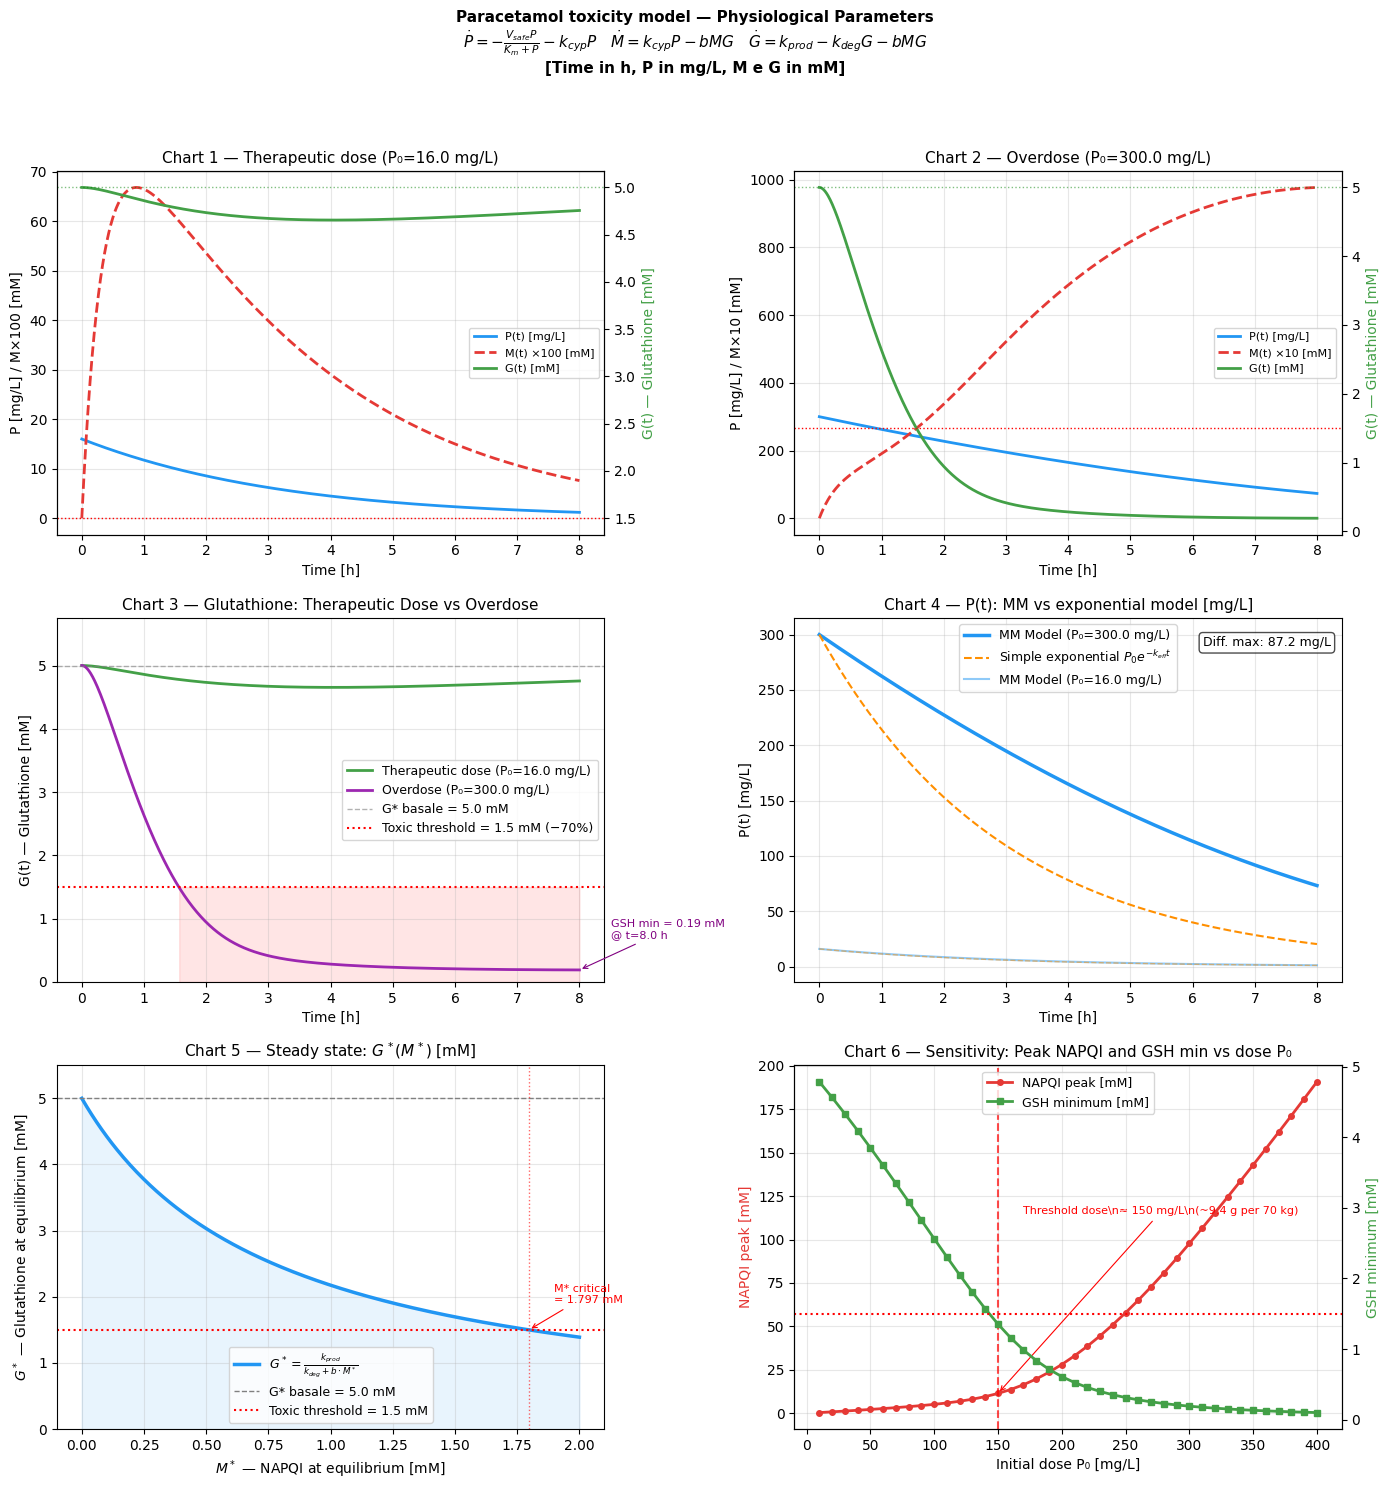

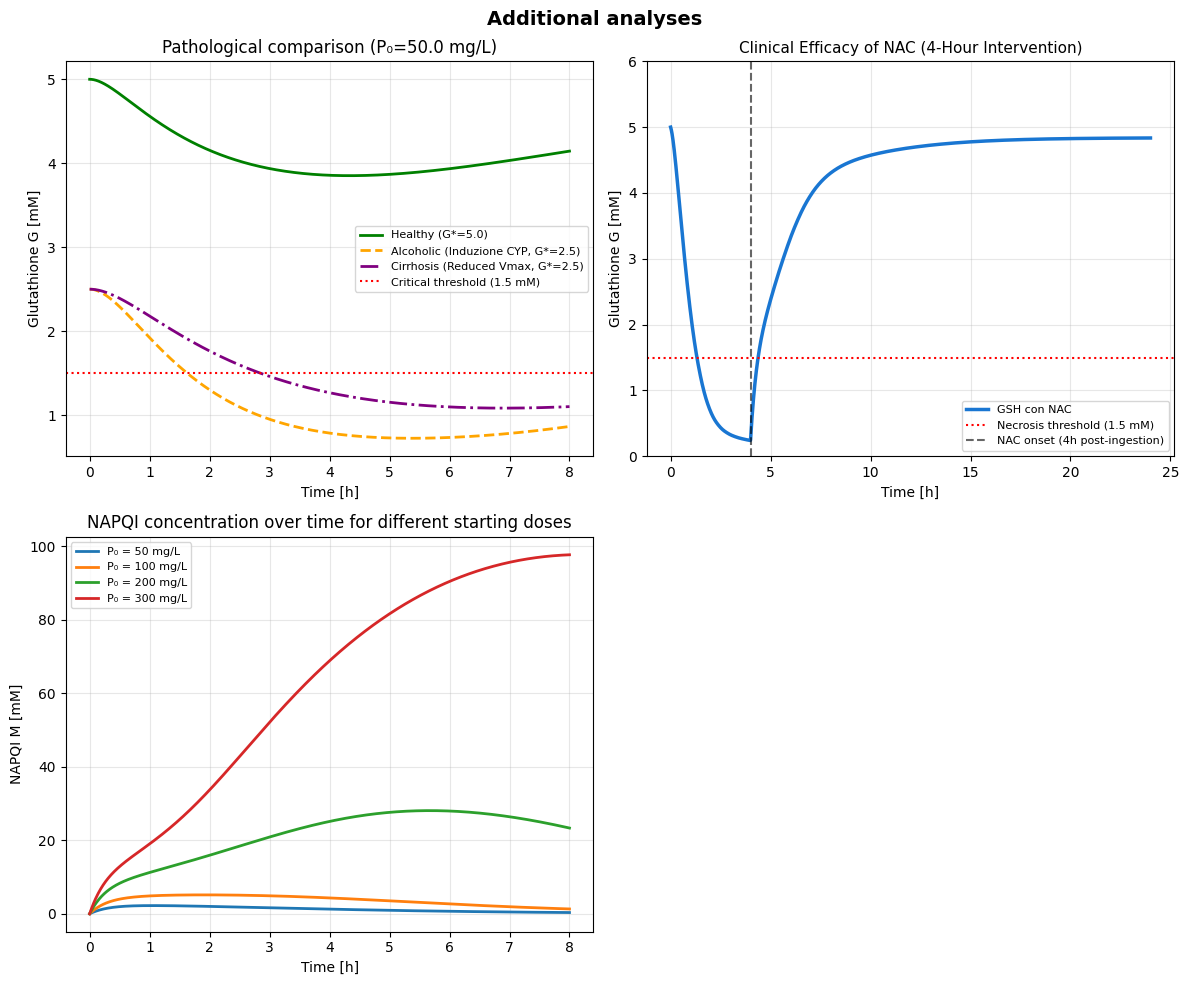


  PHYSIOLOGICAL RESULTS

  --- Therapeutic dose (P₀ = 16.0 mg/L) ---
  NAPQI peak         = 668.1836 µM
  GSH minimun           = 4.655 mM  (93.1% of baseline)
  Liver toxicity    : NO

  --- Overdose (P₀ = 300.0 mg/L) ---
  NAPQI peak          = 97.7322 mM
  Time peak          = 8.00 hours
  GSH minimun           = 0.190 mM  (3.8% of baseline)
  Liver toxicity   : SÌ — expected liver damage

  Toxic threshold dose  ≈ 150 mg/L
  (~9.4 g per 70 kg person, Vd=0.9 L/kg)

  k_eff (linear regime) = 0.00560 min⁻¹
  Diff. max MM vs exp    = 87.16 mg/L


In [2]:
"""
Modeling and Quantitative Approaches to Life Sciences
======================================================
Project work: MODELING THE BIOCHEMICAL THRESHOLD OF ACETAMINOPHEN TOXICITY

Unit of measurement:
    - Time        : minutes [min]
    - Paracetamol : mg/L  (plasma concentration)
    - NAPQI        : mM    (hepatic concentration)
    - GSH   : mM    (hepatic concentration)

ODE system:
    dP/dt = - (V_safe * P) / (K_m + P)  -  k_cyp * P
    dM/dt =   k_cyp * P / MW_APAP * 1000  -  b * M * G
    dG/dt =   kprod  -  kdeg * G  -  d * M * G

1st equation — P [mg/L]:
    The safe pathways (glucuronidation + sulfation, ~90% of the drug)
    follow Michaelis-Menten kinetics with Km ~150 mg/L. At therapeutic doses
    (P<<Km), they behave as first-order; at high doses
    (P≥Km), they saturate, leaving more APAP available for the
    CYP450 and increasing the production of NAPQI.

2nd equation — M [mM]:
    The term k_cyp*P is the same parameter as in eq. 1 (conservation of mass).
    The factor /MW_APAP*1000 converts from mg/L to mM.

3rd equation — G [mM]:
    Steady state: G* = kprod/kdeg = 5 mM.

Parameter sourcess:
    - Prescott (1980) Br J Clin Pharmacol: t½ paracetamol = 1.5-2.5 h
    - Corcoran et al. (1980): 5-9% del paracetamolo → NAPQI via CYP450
    - Andersen et al. (1997) Toxicol Appl Pharmacol: Km glucuronidation
      ~1 mM ≈ 151 mg/L per APAP in human liver
    - Allocati et al. (2021) Antioxidants: GSH basal heaptic 1-10 mM
    - Prescott et al. PMC4753970: toxic threshold >70% depletion GSH
    - Reed et al. (2008) Theor Biol Med Model: half-life GSH ~2-3h
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# =============================================================================
# 1. REAL PHYSIOLOGICAL PARAMETERS
# =============================================================================

# --- Molecular weight of paracetamol (for conversion mg/L → mM) ---
MW_APAP = 151.16    # [g/mol]

# --- P-Equation: Safe Routes (Michaelis-Menten) ---
# Safe pathways (glucuronidation + sulfation) handle ~90% of APAP
# Km ≈ 1 mM ≈ 151 mg/L per APAP (Andersen et al. 1997)
# In linear regime (P<<Km): V_safe/Km ≈ k_safe = 0.9 * k_total
# with k_total = ln(2)/120 ≈ 0.00578 min⁻¹
K_m    = 151.16     # [mg/L]  Michaelis constant (≈ 1 mM)
k_safe = 0.90 * np.log(2) / 120.0   # [1/min] linear constant safe ways
V_safe = k_safe * K_m               # [mg/(L·min)] Vmax = k_safe * Km

# --- P and M equation: via CYP450 ---
# ~7% of the total amount goes to CYP450 (Corcoran et al. 1980)
k_cyp = 0.07 * np.log(2) / 120.0   # [1/min] ~ 4.05e-4 min⁻¹

# --- Equation M: NAPQI neutralization by GSH ---
b = 1.0e-2          # [1/(mM·min)]  (Reed et al. 2008)

# --- Equation G: GSH production and degradation ---
t_half_G  = 180.0                   # [min] half-life GSH (Reed et al. 2008)
kdeg      = np.log(2) / t_half_G    # [1/min] ~ 0.00385 min⁻¹
GSH_basale = 5.0                    # [mM] basal hepatic value
kprod     = kdeg * GSH_basale       # [mM/min] → G* = kprod/kdeg = 5 mM

# --- GSH consumption from NAPQI ---
d = 5.0e-3          # [1/(mM·min)]

# --- Initial conditions ---
P0_terapeutica  = 16.0      # [mg/L]  1g per 70 kg, Vd=0.9 L/kg
P0_sovradosaggio = 300.0    # [mg/L]  Severe overdose

GSH_soglia_tossica = GSH_basale * 0.30     # [mM] 1.5 mM — perdita >70%

# --- Time range: 0-480 min (8 hours) ---
t_start = 0
t_end   = 480
dt      = 0.5
t_eval  = np.arange(t_start, t_end + dt, dt)

print("=" * 60)
print("  REAL PHYSIOLOGICAL PARAMETERS")
print("=" * 60)
print(f"  V_safe (Vmax safe routes) = {V_safe:.4f} mg/(L·min)")
print(f"  K_m    (Michaelis)       = {K_m:.2f} mg/L  ({K_m/MW_APAP*1000:.2f} mM)")
print(f"  k_cyp  (CYP450)          = {k_cyp:.6f} min⁻¹")
print(f"  b      (NAPQI neutral.)  = {b:.4f} 1/(mM·min)")
print(f"  kprod  (GSH synthesis)     = {kprod:.6f} mM/min")
print(f"  kdeg   (GSH degradation)       = {kdeg:.5f} min⁻¹  (t½={t_half_G} min)")
print(f"  d      (GSH consumption)     = {d:.4f} 1/(mM·min)")
print(f"\n  G* = kprod/kdeg          = {kprod/kdeg:.2f} mM  (expected: {GSH_basale} mM)")
print(f"  GSH toxic threshold       = {GSH_soglia_tossica} mM (30% del basale)")

# =============================================================================
# 2. ODE SYSTEM
# =============================================================================

def sistema_ode(t, y, V_safe, K_m, k_cyp, b, kprod, kdeg, d):
    """
    ODE system with real physiological units and new equations

    dP/dt = -(V_safe * P)/(K_m + P)  -  k_cyp * P          [mg/L/min]
    dM/dt =  k_cyp * P / MW_APAP * 1000  -  b * M * G      [mM/min]
    dG/dt =  kprod  -  kdeg * G  -  d * M * G               [mM/min]
    """
    P, M, G = y

    dP_dt = -(V_safe * P) / (K_m + P) - k_cyp * P
    dM_dt =  k_cyp * P / MW_APAP * 1000 - b * M * G
    dG_dt =  kprod - kdeg * G - d * M * G

    if G < 0:
        dG_dt = max(dG_dt, 0)

    return [dP_dt, dM_dt, dG_dt]

# =============================================================================
# 3. NUMERICAL INTEGRATION
# =============================================================================

def integra(P0, V_safe=V_safe, K_m=K_m, k_cyp=k_cyp,
            b=b, kprod=kprod, kdeg=kdeg, d=0.001):
    """Integrate the ODE system starting from the steady state of G"""
    G0 = kprod / kdeg
    y0 = [P0, 0.0, G0]
    sol = solve_ivp(
        fun      = lambda t, y: sistema_ode(t, y, V_safe, K_m, k_cyp,
                                            b, kprod, kdeg, d),
        t_span   = [t_start, t_end],
        y0       = y0,
        method   = 'RK45',
        t_eval   = t_eval,
        max_step = dt,
        rtol     = 1e-8,
        atol     = 1e-10
    )
    return sol

sol_ter  = integra(P0_terapeutica)
sol_over = integra(P0_sovradosaggio)

P_ter,  M_ter,  G_ter  = sol_ter.y
P_over, M_over, G_over = sol_over.y
t = sol_ter.t
t_ore = t / 60.0

# =============================================================================
# 4. COMPARISON WITH SIMPLE EXPONENTIAL
# =============================================================================
# P no longer has an exact analytical solution. Let's compare it with the simple
# exponential solution that would be obtained in the linear regime (P << K_m):
# k_eff = V_safe/K_m + k_cyp (linear approximation)

k_eff        = V_safe / K_m + k_cyp
P_exp_ter    = P0_terapeutica   * np.exp(-k_eff * t)
P_exp_over   = P0_sovradosaggio * np.exp(-k_eff * t)

# =============================================================================
# 5. STEADY STATE G*(M*)
# =============================================================================
# G* = kprod / (kdeg + d*M*)

M_star = np.linspace(0, 2.0, 300)
G_star = kprod / (kdeg + d * M_star)

# =============================================================================
# 6. SENSITIVITY ANALYSIS
# =============================================================================

dosi     = np.linspace(10, 400, 40)
picchi_M = []
minimi_G = []
for P0 in dosi:
    # d=0.001 is the value that brings the threshold to ~150 mg/L (9.4 grams)
    s = integra(P0, d=0.001)
    picchi_M.append(np.max(s.y[1]))
    minimi_G.append(np.min(s.y[2]))

picchi_M = np.array(picchi_M)
minimi_G = np.array(minimi_G)

dosi_tossiche = dosi[minimi_G < GSH_soglia_tossica]
dose_soglia   = dosi_tossiche[0] if len(dosi_tossiche) > 0 else None

# =============================================================================
# 7. CHARTS
# =============================================================================

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
fig.suptitle(
    'Paracetamol toxicity model — Physiological Parameters\n'
    r'$\dot{P}=-\frac{V_{safe}P}{K_m+P}-k_{cyp}P \quad'
    r'\dot{M}=k_{cyp}P-bMG \quad'
    r'\dot{G}=k_{prod}-k_{deg}G-bMG$'
    '\n[Time in h, P in mg/L, M e G in mM]',
    fontsize=11, fontweight='bold', y=0.99
)

colP = '#2196F3'
colM = '#E53935'
colG = '#43A047'
colA = '#FF8F00'
colO = '#9C27B0'

# ---- Chart 1: Therapeutic dose ---------------------------------
ax = axes[0, 0]
ax2 = ax.twinx()
ln1 = ax.plot(t_ore, P_ter,       color=colP, lw=2, label='P(t) [mg/L]')
ln2 = ax.plot(t_ore, M_ter * 100, color=colM, lw=2, ls='--', label='M(t) ×100 [mM]')
ln3 = ax2.plot(t_ore, G_ter,      color=colG, lw=2, label='G(t) [mM]')
ax2.axhline(GSH_soglia_tossica, color='red', lw=1, ls=':', label=f'Toxic threshold = {GSH_soglia_tossica} mM')
ax2.axhline(GSH_basale, color='green', lw=1, ls=':', alpha=0.5, label=f'G* basale = {GSH_basale} mM')
ax2.set_ylabel('G(t) — Glutathione [mM]', color=colG)
ax.set_title(f'Chart 1 — Therapeutic dose (P₀={P0_terapeutica} mg/L)', fontsize=11)
ax.set_xlabel('Time [h]')
ax.set_ylabel('P [mg/L] / M×100 [mM]')
lns = ln1 + ln2 + ln3
labs = [l.get_label() for l in lns]
ax.legend(lns, labs, fontsize=8, loc='center right')
ax.grid(True, alpha=0.3)

# ---- Chart 2: Overdose (300 mg/L) ------------------------------------------
ax = axes[0, 1]
ax2 = ax.twinx()

ln1 = ax.plot(t_ore, P_over,      color=colP, lw=2, label='P(t) [mg/L]')
ln2 = ax.plot(t_ore, M_over * 10,  color=colM, lw=2, ls='--', label='M(t) ×10 [mM]')
ln3 = ax2.plot(t_ore, G_over,      color=colG, lw=2, label='G(t) [mM]')

# Thresholds
ax2.axhline(GSH_soglia_tossica, color='red', lw=1, ls=':', label=f'Soglia tossica')
ax2.axhline(GSH_basale, color='green', lw=1, ls=':', alpha=0.5, label=f'G* basale')

# Titles and labels
ax2.set_ylabel('G(t) — Glutathione [mM]', color=colG)
ax.set_title(f'Chart 2 — Overdose (P₀={P0_sovradosaggio} mg/L)', fontsize=11)
ax.set_xlabel('Time [h]')
ax.set_ylabel('P [mg/L] / M×10 [mM]')

# Unified legend
lns = ln1 + ln2 + ln3
labs = [l.get_label() for l in lns]
ax.legend(lns, labs, fontsize=8, loc='center right')
ax.grid(True, alpha=0.3)

# ---- Chart 3: Comparison of therapeutic GSH vs overdose -----
ax = axes[1, 0]
ax.plot(t_ore, G_ter,  color=colG, lw=2, label=f'Therapeutic dose (P₀={P0_terapeutica} mg/L)')
ax.plot(t_ore, G_over, color=colO, lw=2, label=f'Overdose (P₀={P0_sovradosaggio} mg/L)')
ax.axhline(GSH_basale,         color='gray', lw=1, ls='--', alpha=0.6, label=f'G* basale = {GSH_basale} mM')
ax.axhline(GSH_soglia_tossica, color='red',  lw=1.5, ls=':', label=f'Toxic threshold = {GSH_soglia_tossica} mM (−70%)')
ax.fill_between(t_ore, 0, GSH_soglia_tossica, where=(G_over < GSH_soglia_tossica), alpha=0.1, color='red')
idx_min = np.argmin(G_over)
ax.annotate(f'GSH min = {G_over[idx_min]:.2f} mM\n@ t={t_ore[idx_min]:.1f} h',
            xy=(t_ore[idx_min], G_over[idx_min]),
            xytext=(t_ore[idx_min] + 0.5, G_over[idx_min] + 0.5),
            fontsize=8, color='purple', arrowprops=dict(arrowstyle='->', color='purple', lw=0.8))
ax.set_title('Chart 3 — Glutathione: Therapeutic Dose vs Overdose', fontsize=11)
ax.set_xlabel('Time [h]')
ax.set_ylabel('G(t) — Glutathione [mM]')
ax.set_ylim(0, GSH_basale * 1.15)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# ---- Chart 4: MM vs. Exponential Model ----------------------
ax = axes[1, 1]
ax.plot(t_ore, P_over,     color=colP, lw=2.5, label=f'MM Model (P₀={P0_sovradosaggio} mg/L)')
ax.plot(t_ore, P_exp_over, color=colA, lw=1.5, ls='--', label=r'Simple exponential $P_0 e^{-k_{eff}t}$')
ax.plot(t_ore, P_ter,      color=colP, lw=1.5, alpha=0.5, label=f'MM Model (P₀={P0_terapeutica} mg/L)')
ax.plot(t_ore, P_exp_ter,  color=colA, lw=1.0, ls='--', alpha=0.5)
err_max = np.max(np.abs(P_over - P_exp_over))
ax.text(0.98, 0.95, f'Diff. max: {err_max:.1f} mg/L', transform=ax.transAxes, ha='right', va='top', fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
ax.set_title('Chart 4 — P(t): MM vs exponential model [mg/L]', fontsize=11)
ax.set_xlabel('Time [h]')
ax.set_ylabel('P(t) [mg/L]')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# ---- Chart 5: Steady state G*(M*) -----------------------------
ax = axes[2, 0]
ax.plot(M_star, G_star, color=colP, lw=2.5, label=r'$G^* = \frac{k_{prod}}{k_{deg} + b \cdot M^*}$')
ax.fill_between(M_star, G_star, alpha=0.1, color=colP)
ax.axhline(GSH_basale,         color='gray', lw=1, ls='--', label=f'G* basale = {GSH_basale} mM')
ax.axhline(GSH_soglia_tossica, color='red',  lw=1.5, ls=':', label=f'Toxic threshold = {GSH_soglia_tossica} mM')
M_half_tox = (kprod / GSH_soglia_tossica - kdeg) / d
ax.axvline(M_half_tox, color='red', lw=1, ls=':', alpha=0.6)
ax.annotate(f'M* critical\n= {M_half_tox:.3f} mM', xy=(M_half_tox, GSH_soglia_tossica),
            xytext=(M_half_tox + 0.1, GSH_soglia_tossica + 0.4), fontsize=8, color='red',
            arrowprops=dict(arrowstyle='->', color='red', lw=0.8))
ax.set_title(r'Chart 5 — Steady state: $G^*(M^*)$ [mM]', fontsize=11)
ax.set_xlabel(r'$M^*$ — NAPQI at equilibrium [mM]')
ax.set_ylabel(r'$G^*$ — Glutathione at equilibrium [mM]')
ax.set_ylim(0, GSH_basale * 1.1)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# ---- Graph 6: Sensitivity -------------------------------------
ax = axes[2, 1]
ax2 = ax.twinx()
ln1 = ax.plot(dosi, picchi_M, 'o-', color=colM, lw=2, ms=4, label='NAPQI peak [mM]')
ln2 = ax2.plot(dosi, minimi_G, 's-', color=colG, lw=2, ms=4, label='GSH minimum [mM]')
ax2.axhline(GSH_soglia_tossica, color='red', lw=1.5, ls=':', label=f'Toxic threshold = {GSH_soglia_tossica} mM')
if dose_soglia is not None:
    ax.axvline(dose_soglia, color='red', lw=1.5, ls='--', alpha=0.7)
    ax.annotate(f'Threshold dose\\n≈ {dose_soglia:.0f} mg/L\\n(~{dose_soglia*0.9*70/1000:.1f} g per 70 kg)',
                xy=(dose_soglia, picchi_M[dosi >= dose_soglia][0]),
                xytext=(dose_soglia + 20, picchi_M.max() * 0.6), fontsize=8, color='red',
                arrowprops=dict(arrowstyle='->', color='red', lw=0.8))
ax.set_title('Chart 6 — Sensitivity: Peak NAPQI and GSH min vs dose P₀', fontsize=11)
ax.set_xlabel('Initial dose P₀ [mg/L]')
ax.set_ylabel('NAPQI peak [mM]', color=colM)
ax2.set_ylabel('GSH minimum [mM]', color=colG)
lns = ln1 + ln2
labs = [l.get_label() for l in lns]
ax.legend(lns, labs, fontsize=9, loc='upper center')
ax.grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('paracetamolo_fisiologico_v3.png', dpi=150, bbox_inches='tight')
plt.show()

# =============================================================================
# 8. ADDITIONAL CHARTS
# =============================================================================

P0_moderata = 50.0  # mg/L (~3g of paracetamol)

# 1. HEALTHY
sol_sano = integra(P0_moderata)

# 2. CHRONIC ALCOHOLIC: CYP induction (x2.0) and basal GSH at 2.5 mM (b=d=0,001)
k_cyp_alcol = k_cyp * 2.0
kprod_alcol = kdeg * 2.5
sol_alcol = integra(P0_moderata, k_cyp=k_cyp_alcol, kprod=kprod_alcol, d=0.001)

# 3. LIVER CIRRHOSIS: Reduced Vmax and basal GSH at 2.5 mM
V_safe_cirr = V_safe * 0.5
kprod_cirr = kdeg * 2.5
sol_cirr = integra(P0_moderata, V_safe=V_safe_cirr, kprod=kprod_cirr, d=0.001)

# ---- NAC Clinical Simulation (21-hour protocol) ----
def sistema_clinico_nac(t, y):
    P, M, G = y

    # First injection at 4 hours (240 min) - Clinical critical moment
    t_inizio_nac = 240

    if t < t_inizio_nac:
        mkp = 1.0
        md  = 1.0
    else:
        mkp = 5.0
        md  = 0.3  # NAC neutralizes NAPQI, protecting GSH

    d_eff = 0.001 * md

    # LINEAR SYNTHESIS EQUATION
    # G_max prevents infinite growth but in a smooth manner
    G_max = 6.0
    sintesi_limitata = kprod * mkp * (1 - G/G_max if G < G_max else 0)

    dP_dt = -(V_safe * P) / (K_m + P) - k_cyp * P
    dM_dt = k_cyp * P / 151.16 * 1000 - b * M * G
    dG_dt = sintesi_limitata - kdeg * G - d_eff * M * G

    return [dP_dt, dM_dt, dG_dt]

# 24-hour integration (1440 min)
t_eval_long = np.linspace(0, 1440, 2000)
sol_clinica = solve_ivp(sistema_clinico_nac, [0, 1440], [300, 0, 5],
                        t_eval=t_eval_long, method='RK45')

# ---- 2x2 grid ----
fig_extra, axes_extra = plt.subplots(2, 2, figsize=(12, 10))
fig_extra.suptitle('Additional analyses', fontsize=14, fontweight='bold')

# ---- Chart 1: Pathological comparison ----
ax1 = axes_extra[0, 0]
ax1.clear()

ax1.plot(t_ore, sol_sano.y[2],   'g-',  lw=2, label='Healthy (G*=5.0)')
ax1.plot(t_ore, sol_alcol.y[2],  'orange', lw=2, ls='--', label='Alcoholic (Induzione CYP, G*=2.5)')
ax1.plot(t_ore, sol_cirr.y[2],   'purple', lw=2, ls='-.', label='Cirrhosis (Reduced Vmax, G*=2.5)')

ax1.axhline(1.5, color='red', ls=':', label='Critical threshold (1.5 mM)')
ax1.set_title(f'Pathological comparison (P₀={P0_moderata} mg/L)')
ax1.set_xlabel('Time [h]')
ax1.set_ylabel('Glutathione G [mM]')
ax1.legend(fontsize=8, loc='center right')
ax1.grid(alpha=0.3)

plt.draw()

# ---- Chart 2: Clinical simulation with NAC ----
ax2 = axes_extra[0, 1]
ax2.clear()
ax2.plot(sol_clinica.t/60, sol_clinica.y[2], color='#1976D2', lw=2.5, label='GSH con NAC')
ax2.axhline(1.5, color='red', ls=':', lw=1.5, label='Necrosis threshold (1.5 mM)')
ax2.axvline(4, color='black', ls='--', alpha=0.6, label='NAC onset (4h post-ingestion)')

ax2.set_title('Clinical Efficacy of NAC (4-Hour Intervention)', fontsize=11)
ax2.set_xlabel('Time [h]')
ax2.set_ylabel('Glutathione G [mM]')
ax2.set_ylim(0, 6)
ax2.legend(fontsize=8, loc='lower right')
ax2.grid(alpha=0.3)

# ---- Chart 3: NAPQI trend for different doses ----
ax3 = axes_extra[1, 0]
dosi_NAPQI = [50, 100, 200, 300]
for d in dosi_NAPQI:
    sol = integra(d)
    ax3.plot(t_ore, sol.y[1], lw=2, label=f'P₀ = {d} mg/L')
ax3.set_xlabel('Time [h]')
ax3.set_ylabel('NAPQI M [mM]')
ax3.set_title('NAPQI concentration over time for different starting doses')
ax3.legend(fontsize=8)
ax3.grid(alpha=0.3)

axes_extra[1, 1].axis('off')

plt.tight_layout()
plt.savefig('analisi_aggiuntive_griglia.png', dpi=150, bbox_inches='tight')
plt.show()

# =============================================================================
# 10. NUMERICAL SUMMARY
# =============================================================================
print("\n" + "=" * 60)
print("  PHYSIOLOGICAL RESULTS")
print("=" * 60)
print(f"\n  --- Therapeutic dose (P₀ = {P0_terapeutica} mg/L) ---")
print(f"  NAPQI peak         = {np.max(M_ter)*1000:.4f} µM")
print(f"  GSH minimun           = {np.min(G_ter):.3f} mM  ({np.min(G_ter)/GSH_basale*100:.1f}% of baseline)")
print(f"  Liver toxicity    : {'NO' if np.min(G_ter) > GSH_soglia_tossica else 'SÌ'}")
print(f"\n  --- Overdose (P₀ = {P0_sovradosaggio} mg/L) ---")
print(f"  NAPQI peak          = {np.max(M_over):.4f} mM")
print(f"  Time peak          = {t_ore[np.argmax(M_over)]:.2f} hours")
print(f"  GSH minimun           = {np.min(G_over):.3f} mM  ({np.min(G_over)/GSH_basale*100:.1f}% of baseline)")
print(f"  Liver toxicity   : {'NO' if np.min(G_over) > GSH_soglia_tossica else 'SÌ — expected liver damage'}")
if dose_soglia is not None:
    print(f"\n  Toxic threshold dose  ≈ {dose_soglia:.0f} mg/L")
    print(f"  (~{dose_soglia*0.9*70/1000:.1f} g per 70 kg person, Vd=0.9 L/kg)")
print(f"\n  k_eff (linear regime) = {k_eff:.5f} min⁻¹")
print(f"  Diff. max MM vs exp    = {np.max(np.abs(P_over - P_exp_over)):.2f} mg/L")
print("=" * 60)